#  India's Pharmaceutical Import Dependence on China, 2003 to 2024

**Question:** How dependent is India on China for pharmaceutical imports, and where is the dependence heading?

**Data:** Cleaned WITS-Comtrade data for about 430 pharmaceutical products (HS 6-digit codes), 2003 to 2024. It has India's global imports, global exports, and imports from China, in US$ thousand.

**Data notes:** Blank cells were treated as zero trade. In two products, China's early-year figure was higher than the world figure, so shares were capped at 100%. Two products with no imports in the early or recent period were left out of the grouping.

In [1]:
import pandas as pd
import numpy as np

In [2]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\KALPANA\Downloads\Documents\business analytics using python\Project
['.ipynb_checkpoints', 'FINAL dataset containing all.xlsx', 'part1_forecast.png', 'part1_forecast_table.csv', 'part2_groups.png', 'part2_group_summary.csv', 'part2_top10_products.csv', 'part3_crossed_products.csv', 'part3_feature_importance.png', 'part3_model_results.csv', 'project_1.ipynb']


In [3]:
import matplotlib.pyplot as plt

In [4]:
f = 'FINAL dataset containing all.xlsx'

def load(sheet, hdr):
    df = pd.read_excel(f, sheet_name=sheet, header=hdr)
    df = df.rename(columns={df.columns[0]: 'hs6'})
    df = df[pd.to_numeric(df['hs6'], errors='coerce').notna()].copy()
    df['hs6'] = df['hs6'].astype(int)
    df.columns = ['hs6'] + [int(float(c)) for c in df.columns[1:]]
    return df.set_index('hs6').fillna(0)

exports = load('globa exports', 1)
imports = load('global imports', 1)
china   = load('china imports', 0).reindex(imports.index).fillna(0)

print(exports.shape, imports.shape, china.shape)

(431, 22) (432, 22) (432, 22)


In [5]:
imports.head()


,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
hs6,,,,,,,,,,,,,,,,,,,,,
150500,1029.285,1273.473,1317.918,1273.827,1428.257,953.673,1645.492,2144.140,1469.993,3178.187,...,2598.058,1609.865,2321.209,2015.734,3105.277,4761.044,9054.144,8457.986,5487.159,5540.508
152000,3026.776,3383.854,2836.898,2324.154,5062.220,16143.117,3565.657,1938.981,4284.364,4397.689,...,5602.890,8664.526,11997.877,40365.681,23110.723,27374.215,74108.459,86864.453,39291.666,43665.046
170211,5873.337,6352.762,6052.551,10462.467,16582.396,16860.604,17241.545,24076.169,36764.786,39914.276,...,40792.283,40140.689,52809.068,48631.458,53920.821,66190.025,69308.715,72378.653,100820.221,85745.598
170219,3757.578,4006.470,2624.391,2438.831,5443.139,5601.530,5489.334,6685.080,12189.402,10699.160,...,7309.766,9256.841,14813.240,19081.099,16479.410,21735.064,24790.918,14980.791,28973.968,24736.516
170230,624.378,275.285,112.539,194.734,3861.969,1229.067,698.028,5453.513,4946.114,1356.835,...,2215.472,1234.696,1984.073,1539.838,1544.636,1680.300,1591.039,1660.070,2934.108,2219.460


2003    18.7
2004    18.2
2005    20.4
2006    23.3
2007    26.4
2008    28.7
2009    29.3
2010    28.0
2011    27.2
2012    27.3
2013    26.6
2014    29.6
2015    32.9
2016    30.8
2017    29.3
2018    31.1
2019    32.0
2020    34.3
2021    32.7
2022    35.0
2023    34.5
2024    32.9
dtype: float64


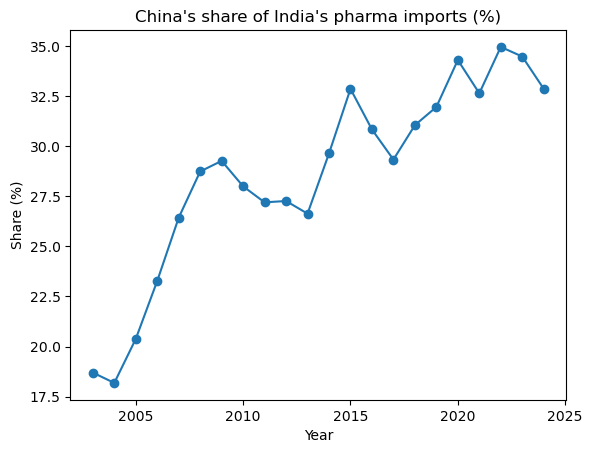

In [6]:
share = (china.sum() / imports.sum() * 100).astype(float)
share.index = share.index.astype(int)
print(share.round(1))

share.plot(marker='o')
plt.title("China's share of India's pharma imports (%)")
plt.xlabel('Year')
plt.ylabel('Share (%)')
plt.show()

#  Part 1: Forecast

China's share of India's pharmaceutical imports rose from 18.7% in 2003 to 32.9% in 2024, about 0.76 percentage points a year on the linear trend. I trained a linear and a logistic trend on 2003 to 2019 and tested them on 2020 to 2024. The linear trend had the smaller error (RMSE 2.18 against 3.08).

Both models overshoot the recent years, because the share has stayed at about 33% to 35% since 2020. The 2030 forecasts (41.5% linear, 44.2% logistic) show what would happen if the 2003 to 2019 trend continued. They are upper-end scenarios, not predictions.

In [7]:
years = share.index.values.astype(int)
train = years <= 2019      # years the model learns from
test  = years >= 2020      # years we hide, then check

# Model A: straight-line trend
b_lin, a_lin = np.polyfit(years[train], share.values[train], 1)
lin_fit = lambda y: a_lin + b_lin * np.asarray(y)

# Model B: S-shaped (logistic) trend, a straight line on the log-odds
p = share.values / 100
logit = np.log(p / (1 - p))
b_log, a_log = np.polyfit(years[train], logit[train], 1)
log_fit = lambda y: 100 / (1 + np.exp(-(a_log + b_log * np.asarray(y))))

def rmse(actual, pred):
    return np.sqrt(np.mean((actual - pred) ** 2))

print('Linear RMSE:  ', round(rmse(share.values[test], lin_fit(years[test])), 2))
print('Logistic RMSE:', round(rmse(share.values[test], log_fit(years[test])), 2))
print('Linear slope per year:', round(b_lin, 2))

future = np.arange(2025, 2031)
fc = pd.DataFrame({'year': future,
                   'linear': lin_fit(future).round(1),
                   'logistic': log_fit(future).round(1)})
print(fc)

Linear RMSE:   2.18
Logistic RMSE: 3.08
Linear slope per year: 0.76
   year  linear  logistic
0  2025    37.7      39.3
1  2026    38.5      40.2
2  2027    39.2      41.2
3  2028    40.0      42.2
4  2029    40.7      43.2
5  2030    41.5      44.2


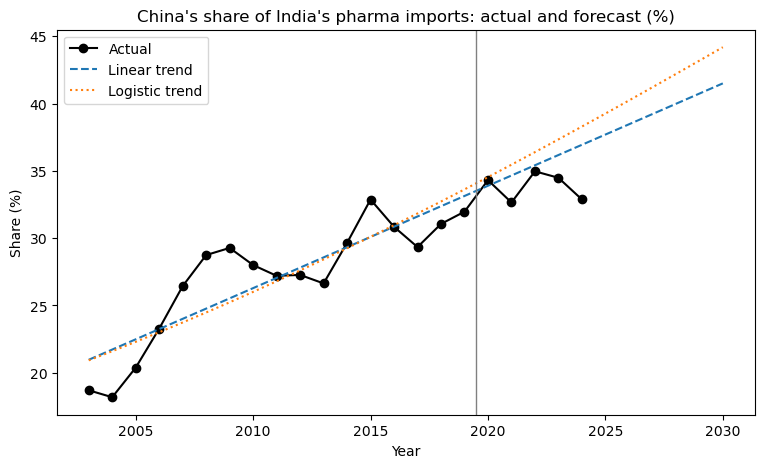

In [8]:
allyears = np.arange(2003, 2031)
plt.figure(figsize=(9, 5))
plt.plot(years, share.values, 'ko-', label='Actual')
plt.plot(allyears, lin_fit(allyears), '--', label='Linear trend')
plt.plot(allyears, log_fit(allyears), ':', label='Logistic trend')
plt.axvline(2019.5, color='grey', linewidth=1)
plt.title("China's share of India's pharma imports: actual and forecast (%)")
plt.xlabel('Year')
plt.ylabel('Share (%)')
plt.legend()
plt.show()

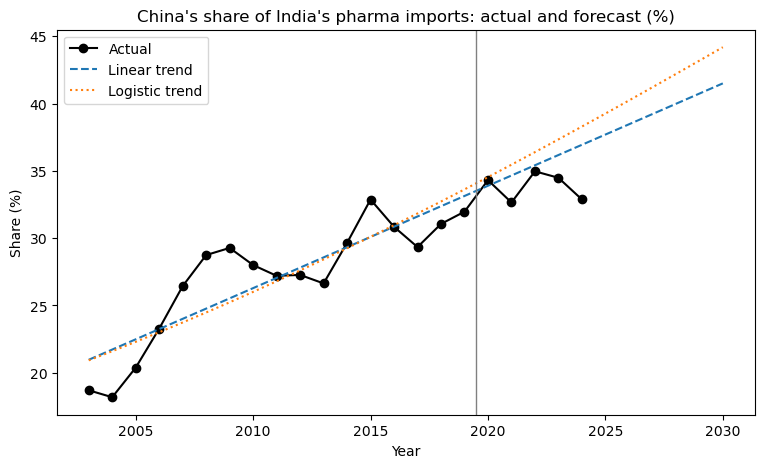

In [9]:
allyears = np.arange(2003, 2031)
plt.figure(figsize=(9, 5))
plt.plot(years, share.values, 'ko-', label='Actual')
plt.plot(allyears, lin_fit(allyears), '--', label='Linear trend')
plt.plot(allyears, log_fit(allyears), ':', label='Logistic trend')
plt.axvline(2019.5, color='grey', linewidth=1)
plt.title("China's share of India's pharma imports: actual and forecast (%)")
plt.xlabel('Year')
plt.ylabel('Share (%)')
plt.legend()
plt.savefig('part1_forecast.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
early = list(range(2003, 2009))
late  = list(range(2020, 2025))

imp_e, imp_l = imports[early].sum(axis=1), imports[late].sum(axis=1)
chn_e, chn_l = china[early].sum(axis=1), china[late].sum(axis=1)

# keep only products with imports in both periods
keep = (imp_e > 0) & (imp_l > 0)
print('Products kept:', int(keep.sum()), 'of', len(imports))

share_e = (chn_e[keep] / imp_e[keep] * 100).clip(0, 100)
share_l = (chn_l[keep] / imp_l[keep] * 100).clip(0, 100)

feat = pd.DataFrame(index=imports.index[keep])
feat['share_recent']  = share_l
feat['share_change']  = share_l - share_e
feat['log_size']      = np.log10(imp_l[keep] / len(late))
feat['import_growth'] = (np.log(imp_l[keep] / len(late)) - np.log(imp_e[keep] / len(early))).clip(-3, 5)

feat.describe().round(1)

Products kept: 430 of 432


,share_recent,share_change,log_size,import_growth
count,430.0,430.0,430.0,430.0
mean,40.1,9.8,4.1,1.3
std,32.4,26.7,1.1,1.5
min,0.0,-89.0,-0.7,-3.0
25%,8.5,-1.7,3.5,0.9
50%,36.5,6.4,4.3,1.5
75%,69.7,25.7,4.8,2.0
max,100.0,99.9,6.2,5.0


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = StandardScaler().fit_transform(feat)   # put all four numbers on the same scale

for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    print('k =', k, ' silhouette =', round(silhouette_score(X, km.labels_), 3))

km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
feat['cluster'] = km.labels_

summary = feat.groupby('cluster').agg(
    products=('cluster', 'size'),
    share_recent=('share_recent', 'mean'),
    share_change=('share_change', 'mean'),
    log_size=('log_size', 'mean'),
    import_growth=('import_growth', 'mean')).round(1)
display(summary)

feat['chapter'] = feat.index // 10000
display(pd.crosstab(feat['cluster'], feat['chapter']))

C:\Users\KALPANA\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\KALPANA\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\KALPANA\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\KALPANA\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\KALPANA\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi

k = 2  silhouette = 0.296


C:\Users\KALPANA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [ ]:
names = {2: 'High and rising dependence',
         1: 'Low dependence, large trade',
         0: 'Small and shrinking trade'}
feat['group'] = feat['cluster'].map(names)

plt.figure(figsize=(9, 6))
for g, d in feat.groupby('group'):
    plt.scatter(d['log_size'], d['share_recent'], label=g, alpha=0.6)
plt.xlabel('Import size, 2020-24 (log10, US$ thousand per year)')
plt.ylabel("China's share, 2020-24 (%)")
plt.title('Pharma products grouped by dependence on China')
plt.legend()
plt.savefig('part2_groups.png', dpi=150, bbox_inches='tight')
plt.show()

top = feat[feat['group'] == 'High and rising dependence'].sort_values('log_size', ascending=False)
display(top.head(10)[['share_recent', 'share_change', 'log_size']].round(1))

# # Part 2: Grouping products by dependence

I described each of 430 products with four numbers: China's share in 2020 to 2024, the change in that share since 2003 to 2008, the size of its imports, and the growth of its imports. K-means clustering worked best with three groups (silhouette score 0.334).

The high and rising group has 178 products, with a China share of about 70% that has risen by about 29 points. Of these, 172 are in HS chapters 28 and 29 (chemicals and drug ingredients) and only 3 are finished medicines (chapter 30). The low-dependence group has 205 products (share about 16%), and 47 products are small and shrinking. The groups overlap at the edges, so the grouping is a guide and not a sharp line.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

e_yrs = list(range(2003, 2010))   # early period
r_yrs = list(range(2015, 2020))   # recent period (last years the model may see)

imp_e, imp_r = imports[e_yrs].sum(axis=1), imports[r_yrs].sum(axis=1)
chn_e, chn_r = china[e_yrs].sum(axis=1), china[r_yrs].sum(axis=1)
imp_24, chn_24 = imports[2024], china[2024]

ok = (imp_e > 0) & (imp_r > 0) & (imp_24 > 0)
print('Products used:', int(ok.sum()))

share_e = (chn_e[ok] / imp_e[ok] * 100).clip(0, 100)
share_r = (chn_r[ok] / imp_r[ok] * 100).clip(0, 100)

data = pd.DataFrame(index=imports.index[ok])
data['share_1519']   = share_r
data['share_change'] = share_r - share_e
data['log_size']     = np.log10(imp_r[ok] / len(r_yrs))
data['growth']       = (np.log(imp_r[ok] / len(r_yrs)) - np.log(imp_e[ok] / len(e_yrs))).clip(-3, 5)
ch = data.index // 10000
data['chap28'] = (ch == 28).astype(int)
data['chap29'] = (ch == 29).astype(int)
data['chap30'] = (ch == 30).astype(int)

# target: 1 if China's share in 2024 is above 50%
y = ((chn_24[ok] / imp_24[ok] * 100) > 50).astype(int)
print('High-dependence products in 2024:', int(y.sum()), 'of', len(y))

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

X_tr, X_te, y_tr, y_te = train_test_split(data, y, test_size=0.2, random_state=42, stratify=y)

# simple rule to beat: "if share was above 50% in 2015-19, it is still above 50% in 2024"
base = (X_te['share_1519'] > 50).astype(int)
print('Simple rule: accuracy', round(accuracy_score(y_te, base), 3), ' F1', round(f1_score(y_te, base), 3))

models = {'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          'Random forest': RandomForestClassifier(n_estimators=300, random_state=42)}

rows = []
for name, m in models.items():
    m.fit(X_tr, y_tr)
    pred, prob = m.predict(X_te), m.predict_proba(X_te)[:, 1]
    cv = cross_val_score(m, data, y, cv=5, scoring='roc_auc').mean()
    rows.append([name, accuracy_score(y_te, pred), f1_score(y_te, pred), roc_auc_score(y_te, prob), cv])

results = pd.DataFrame(rows, columns=['model', 'accuracy', 'F1', 'ROC_AUC', 'CV_AUC']).round(3)
display(results)

rf = models['Random forest']
display(pd.Series(rf.feature_importances_, index=data.columns).sort_values(ascending=False).round(3))
print(confusion_matrix(y_te, rf.predict(X_te)))

In [ ]:
from sklearn.model_selection import cross_val_predict

feats = list(X_tr.columns)
rf2 = RandomForestClassifier(n_estimators=300, random_state=42)
data['prob_high'] = cross_val_predict(rf2, data[feats], y, cv=5, method='predict_proba')[:, 1]

crossed = data[(data['share_1519'] <= 50) & (y == 1)]
print('Below 50% in 2015-19 but above 50% in 2024:', len(crossed))
print('Flagged by the model (probability above 0.5):', int((crossed['prob_high'] > 0.5).sum()))
display(crossed.sort_values('prob_high', ascending=False).head(10)[['share_1519', 'share_change', 'prob_high']].round(2))

# # Part 3: Predicting high-dependence products

Using only data up to 2019, I predicted which of 418 products would have a China share above 50% in 2024 (168 of them did). The random forest reached an ROC-AUC of 0.90 and an accuracy of 0.833. Of the 34 truly high products in the test set it found 24, with 4 false alarms.

A simple rule ("still above 50% if it was above 50% in 2015 to 2019") already gives an accuracy of 0.821, so the models add only a small gain. The 2015 to 2019 share is the strongest predictor. Of the 43 products that crossed 50% after 2019, the model flagged only 2, so it is not a reliable early-warning tool.

In [ ]:
# Part 1 table
fc.to_csv('part1_forecast_table.csv', index=False)

# Part 2 tables
summary.to_csv('part2_group_summary.csv')
top.head(10)[['share_recent', 'share_change', 'log_size']].round(1).to_csv('part2_top10_products.csv')

# Part 3 tables
results.to_csv('part3_model_results.csv', index=False)
crossed.sort_values('prob_high', ascending=False).head(10)[['share_1519', 'share_change', 'prob_high']].round(2).to_csv('part3_crossed_products.csv')

# Part 3 chart: which signals matter most
feats = list(X_tr.columns)
importance = pd.Series(rf.feature_importances_, index=feats).sort_values()
importance.plot(kind='barh', figsize=(7, 4))
plt.title('What predicts high dependence on China in 2024')
plt.xlabel('Importance')
plt.savefig('part3_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# # Limits

The data has trade values only, with no quantities or prices, so price effects cannot be separated from volume. The forecast uses only 22 yearly points. The results show patterns, not causes.